# Mean-element parareal: the Solar System on many cores

This notebook shows how to integrate the Solar System in parallel in time with mean-element parareal (MEP), using the setup of the paper *Mean-element Parareal: Parallel-in-Time Integration of the Solar System* (Hippke, submitted): the Sun and the eight planets, WHFast512 with a time step of 6 days, symplectic correctors of order 17 and the general relativistic correction.

MEP cuts the time axis into slices of 60000 steps (986 years) and processes them in windows of one slice per core. Within a window, all slices are integrated at the same time with WHFast512, each from a guessed start state; a cheap coarse propagator in mean orbital elements links them, and a few parareal iterations make the window converge to the serial trajectory.

The point here is *how* to run MEP and how to check its result, not a long integration: we integrate about 10 windows (some $10^5$ years), which takes a few seconds, and compare the result with a serial WHFast512 integration. A 5 Gyr run works in exactly the same way, only with a larger `tmax` (and a checkpoint file, see the [MEP tutorial](MEP.ipynb) on stopping and resuming).

**Requirements.** Linux or macOS; a central object and exactly eight planets, ordered by distance; the WHFast512 integrator; units with $G=1$.

## Setting up the Solar System

In [1]:
import parachron
import numpy as np
import matplotlib.pyplot as plt

def solar_system():
    sim = parachron.Simulation()
    sim.add("solar system")            # built-in initial conditions (Sun + 8 planets)
    sim.integrator = "whfast512"
    sim.dt = 6.0/365.25*2.*np.pi       # 6 days (time unit: yr/2pi)
    sim.exact_finish_time = False
    sim.integrator.gr_potential = 1    # general relativity
    sim.integrator.corrector = 17      # symplectic correctors of order 17
    return sim

names = ["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", "Uranus", "Neptune"]
masses = [p.m for p in solar_system().particles]

## The MEP run

`parachron.MEP` takes the simulation and uses one thread per physical core. Its tolerance `tol` (default $2\times10^{-6}$ AU) is the stopping rule: a window is accepted when no planet moves by more than `tol` between two iterations.

To look at the trajectory *inside* the run, we set a `heartbeat`. It is called after every completed window, and `mep.boundaries` then holds the end states of all slices of that window as Jacobi elements $(\ln a, \lambda, e\cos\varpi, e\sin\varpi, \sin\frac{i}{2}\cos\Omega, \sin\frac{i}{2}\sin\Omega)$ of the eight planets. The heartbeat holds up the next window while it runs, so it should only store data.

In [2]:
sim = solar_system()
mep = parachron.MEP(sim)
slice_length = mep.window_length/mep.cores
print(f"{mep.cores} cores: one slice = {slice_length/2/np.pi:.0f} yr, one window = {mep.window_length/2/np.pi:.0f} yr")

mep_t, mep_el = [], []
def heartbeat(m):
    b = m.boundaries
    for s, E in enumerate(b):
        mep_t.append(m.t - (len(b)-1-s)*slice_length)
        mep_el.append(E)
mep.heartbeat = heartbeat

nwin = 10
mep.integrate(nwin*mep.window_length)
print(f"t = {mep.t/2/np.pi:.0f} yr after {mep.windows} windows")
print(f"iterations per window: {mep.iterations}, mean {mep.mean_iterations:.2f}")

14 cores: one slice = 986 yr, one window = 13799 yr
t = 137988 yr after 10 windows
iterations per window: {3: 2, 4: 8}, mean 3.80


After `integrate`, `sim` holds the end state as an ordinary simulation. The slice boundaries recorded by the heartbeat are converted to simulations with the same Jacobi convention (each planet orbits the centre of mass of the bodies inside its orbit).

In [3]:
def elements_to_sim(E):
    s = parachron.Simulation()
    s.add(m=masses[0])
    for m, (lna, l, k, h, q, p) in zip(masses[1:], E):
        s.add(m=m, a=np.exp(lna), l=l, e=np.hypot(k, h), pomega=np.arctan2(h, k),
              inc=2.*np.arcsin(np.hypot(q, p)), Omega=np.arctan2(p, q))   # Jacobi: primary = interior centre of mass
    s.move_to_com()
    return s

mep_sims = [elements_to_sim(E) for E in mep_el]
print(f"{len(mep_sims)} slice boundaries, last at t = {mep_t[-1]/2/np.pi:.0f} yr (sim.t = {sim.t/2/np.pi:.0f} yr)")

140 slice boundaries, last at t = 137988 yr (sim.t = 137988 yr)


## Serial reference

For comparison, we integrate the same time span with ordinary serial WHFast512, one slice per call (`concatenate_steps`) and with `jacobi_recursive = 1`, the synchronization that MEP uses.

How close should MEP be? We use two yardsticks: a serial *twin* whose initial $x$ coordinate of Mercury is changed in the last bit (the Solar System is chaotic, so even round-off makes two runs drift apart), and a serial run with a time step of 4 instead of 6 days, whose difference from the 6-day run is the serial integrator's own time-step error.

In [4]:
def serial(perturb=False, steps_per_slice=60000):
    s = solar_system()
    s.dt = slice_length/steps_per_slice
    if perturb:
        s.particles[1].x = np.nextafter(s.particles[1].x, np.inf)    # one ulp
    s.integrator.jacobi_recursive = 1
    s.integrator.concatenate_steps = steps_per_slice                 # one call per slice
    s.move_to_com()
    out = []
    for _ in range(len(mep_sims)):
        s.steps(1)
        out.append(s.copy())
    return out

ser_sims, twin_sims = serial(), serial(perturb=True)
dt4_sims = serial(steps_per_slice=90000)                             # dt = 4 days
print(f"serial: t = {ser_sims[-1].t/2/np.pi:.0f} yr")

serial: t = 137988 yr


## Figure 1: the orbits

Eccentricities and inclinations of the four inner planets, whose short-period terms the coarse step handles by perturbation theory. Lines: serial WHFast512; dots: MEP slice boundaries.

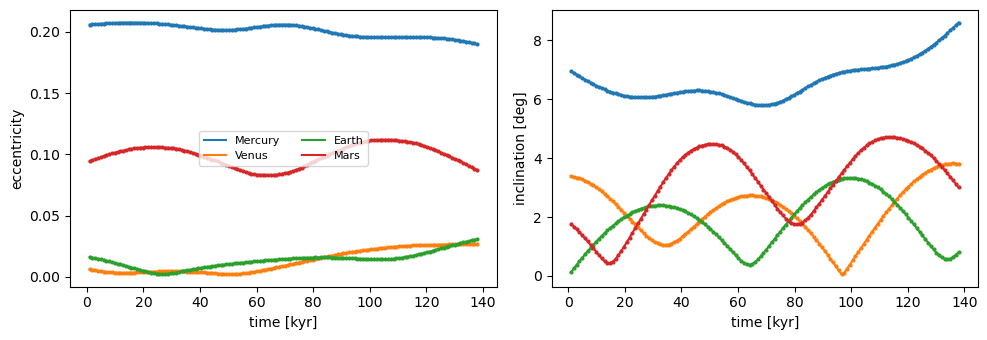

In [5]:
t_kyr = np.array(mep_t)/2/np.pi/1e3
def elements(sims):
    o = np.array([[(p.e, np.degrees(p.inc)) for p in s.orbits()] for s in sims])   # Jacobi elements
    return o[:, :, 0], o[:, :, 1]
e_ser, i_ser = elements(ser_sims)
e_mep, i_mep = elements(mep_sims)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for j in range(4):
    c = f"C{j}"
    axs[0].plot(t_kyr, e_ser[:, j], c=c, label=names[j])
    axs[0].plot(t_kyr, e_mep[:, j], ".", c=c, ms=4)
    axs[1].plot(t_kyr, i_ser[:, j], c=c)
    axs[1].plot(t_kyr, i_mep[:, j], ".", c=c, ms=4)
axs[0].set_ylabel("eccentricity")
axs[1].set_ylabel("inclination [deg]")
for ax in axs:
    ax.set_xlabel("time [kyr]")
axs[0].legend(ncol=2, fontsize=8)
fig.tight_layout()

## Figure 2: how close is MEP to the serial run?

The largest difference in planet position between MEP and serial WHFast512 at every slice boundary. Within the first window, MEP agrees with the serial run as well as the round-off twin does. Every window end leaves a residual of the parareal iteration below the tolerance `tol` (dashed line), which then grows by Kepler shear and chaos like any other small perturbation, so after $10^5$ years MEP differs from the serial run by more than the twin does. All of it stays about a hundred times below the serial integrator's own time-step error (4-day minus 6-day run). Over long times, MEP and serial runs are statistically indistinguishable: in the paper, their secular frequencies agree to within $10^{-7}$ ″/yr over 10 Myr, far below the effect of the serial time step.

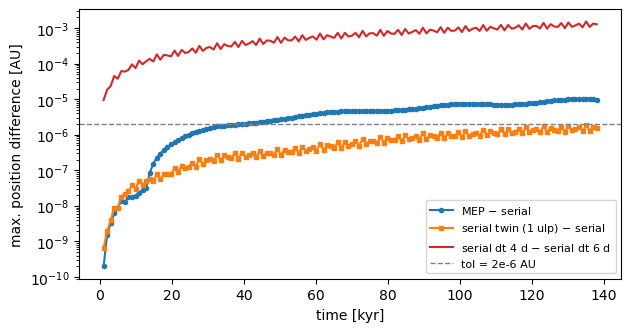

In [6]:
def max_distance(A, B):
    return np.array([max(np.linalg.norm(np.array(a.particles[i].xyz) - np.array(b.particles[i].xyz)) for i in range(1, 9))
                     for a, b in zip(A, B)])

d_mep = max_distance(mep_sims, ser_sims)
d_twin = max_distance(twin_sims, ser_sims)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(t_kyr, d_mep, "o-", ms=3, label="MEP $-$ serial")
ax.semilogy(t_kyr, d_twin, "s-", ms=3, label="serial twin (1 ulp) $-$ serial")
ax.semilogy(t_kyr, max_distance(dt4_sims, ser_sims), "-", c="C3", label="serial dt 4 d $-$ serial dt 6 d")
ax.axhline(2e-6, ls="--", c="gray", lw=1, label="tol = 2e-6 AU")
ax.set_xlabel("time [kyr]")
ax.set_ylabel("max. position difference [AU]")
ax.legend(fontsize=8);

## Figure 3: energy and iterations

Left: the relative energy error of MEP and of the serial run (Newtonian energy of the nine bodies, so it also contains the small periodic contribution of the relativistic term). The two curves lie on top of each other. Right: the number of parareal iterations each window needed; three to four iterations per window are typical for the Solar System on 16 cores.

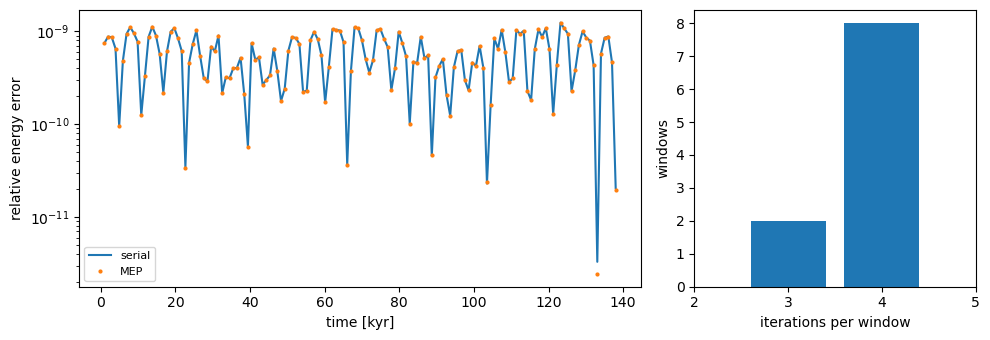

In [7]:
E0 = solar_system().energy()
dE_ser = [abs((s.energy() - E0)/E0) for s in ser_sims]
dE_mep = [abs((s.energy() - E0)/E0) for s in mep_sims]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [2, 1]})
axs[0].semilogy(t_kyr, dE_ser, label="serial")
axs[0].semilogy(t_kyr, dE_mep, ".", ms=4, label="MEP")
axs[0].set_xlabel("time [kyr]")
axs[0].set_ylabel("relative energy error")
axs[0].legend(fontsize=8)
k, n = zip(*sorted(mep.iterations.items()))
axs[1].bar(k, n)
axs[1].set_xticks(range(min(k)-1, max(k)+2))
axs[1].set_xlabel("iterations per window")
axs[1].set_ylabel("windows")
fig.tight_layout()

## Going further

* **Long runs.** Pass `checkpoint="run.mep"` and integrate to any `tmax`, e.g. `mep.integrate(5e9*2*np.pi)` for 5 Gyr. `integrate(tmax, walltime=...)` stops after a given wall-clock time; `parachron.MEP.from_checkpoint("run.mep")` continues the run bitwise identically (see the [MEP tutorial](MEP.ipynb)).
* **Speed.** MEP needs idle physical cores: the speed-up over serial WHFast512 is about 3.3 on 16 cores and 6.7 on 64 cores (5 Gyr runs in the paper). On a machine with few or busy cores it can be slower than a serial run.
* **Accuracy.** The default `tol = 2e-6` gives the accuracy of serial WHFast512; `tol = 3e-6` and `1e-5` are faster and were validated by ensembles of integrations. On 32 or more cores, also set `k_max = 8`.
* **C.** The same is available through `reb_mep_create`, `reb_mep_integrate`, `reb_mep_update_simulation` and `reb_mep_free` (see `examples/mep_solar_system`).